In [3]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles in this directory:")
print(os.listdir())

Current working directory:
d:\IPL_MATCH_PREDICTOR\notebooks

Files in this directory:
['eda.ipynb']


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load our IPL match dataset
df = pd.read_csv("../data/processed/match_summary.csv")
# Display settings
pd.set_option("display.max_columns", None)

print("Dataset shape:", df.shape)
print("Total matches:", len(df))
print("Unique seasons:", df["season"].nunique())

df.head()

Dataset shape: (1243, 20)
Total matches: 1243
Unique seasons: 19


,match_id,season,date,venue,team1,team2,toss_winner,toss_decision,winner,innings_count,innings1_team,innings1_runs,innings1_wickets,innings1_legal_balls,innings1_deliveries,innings2_team,innings2_runs,innings2_wickets,innings2_legal_balls,innings2_deliveries
0,1082591,2017,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bangalore,field,Sunrisers Hyderabad,2,Sunrisers Hyderabad,207,4,120,125,Royal Challengers Bangalore,172.0,10.0,118.0,123.0
1,1082592,2017,2017-04-06,Maharashtra Cricket Association Stadium,Rising Pune Supergiant,Mumbai Indians,Rising Pune Supergiant,field,Rising Pune Supergiant,2,Mumbai Indians,184,8,120,125,Rising Pune Supergiant,187.0,3.0,119.0,122.0
2,1082593,2017,2017-04-07,Saurashtra Cricket Association Stadium,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,field,Kolkata Knight Riders,2,Gujarat Lions,183,4,120,122,Kolkata Knight Riders,184.0,0.0,89.0,96.0
3,1082594,2017,2017-04-08,Holkar Cricket Stadium,Kings XI Punjab,Rising Pune Supergiant,Kings XI Punjab,field,Kings XI Punjab,2,Rising Pune Supergiant,163,6,120,125,Kings XI Punjab,164.0,4.0,114.0,122.0
4,1082595,2017,2017-04-08,M.Chinnaswamy Stadium,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,bat,Royal Challengers Bangalore,2,Royal Challengers Bangalore,157,8,120,124,Delhi Daredevils,142.0,9.0,120.0,124.0


In [5]:
completed = df.dropna(subset=["winner"])

team_wins = completed["winner"].value_counts()

print("Top 10 IPL teams by recorded wins:")
display(team_wins.head(10).to_frame("Wins"))

Top 10 IPL teams by recorded wins:


,Wins
winner,
Mumbai Indians,155
Chennai Super Kings,148
Kolkata Knight Riders,140
Rajasthan Royals,123
Royal Challengers Bangalore,114
Sunrisers Hyderabad,102
Kings XI Punjab,85
Delhi Daredevils,67
Delhi Capitals,58


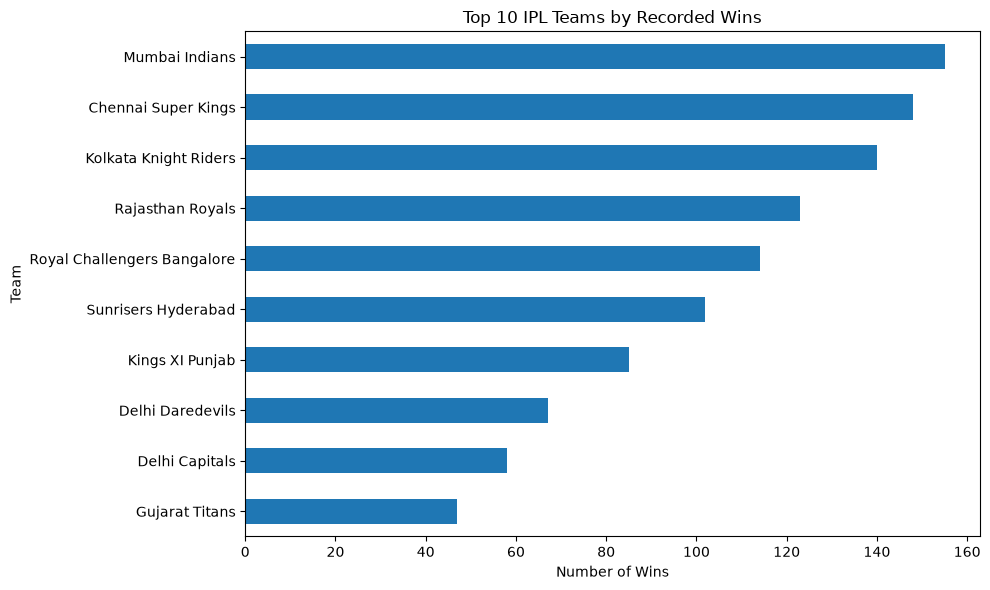

In [6]:
import matplotlib.pyplot as plt

top_10 = team_wins.head(10).sort_values()

plt.figure(figsize=(10, 6))
top_10.plot(kind="barh")

plt.title("Top 10 IPL Teams by Recorded Wins")
plt.xlabel("Number of Wins")
plt.ylabel("Team")
plt.tight_layout()
plt.show()

,Matches
toss_decision,
field,825
bat,418


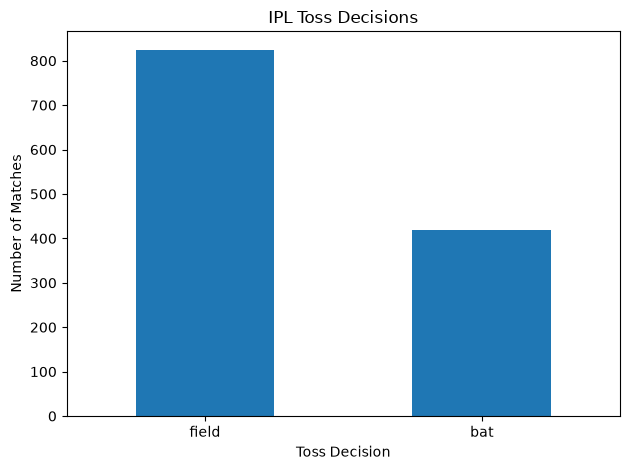

In [7]:
toss_decisions = df["toss_decision"].value_counts()

display(toss_decisions.to_frame("Matches"))

toss_decisions.plot(kind="bar")

plt.title("IPL Toss Decisions")
plt.xlabel("Toss Decision")
plt.ylabel("Number of Matches")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [8]:
valid = df.dropna(subset=["winner", "toss_winner"]).copy()

valid["toss_winner_won_match"] = (
    valid["toss_winner"] == valid["winner"]
)

toss_win_rate = valid["toss_winner_won_match"].mean() * 100

print("Matches analysed:", len(valid))
print(f"Toss winners who also won the match: {toss_win_rate:.2f}%")
print(
    valid["toss_winner_won_match"]
    .value_counts()
    .rename(index={True: "Won match", False: "Lost match"})
)

Matches analysed: 1218
Toss winners who also won the match: 51.56%
toss_winner_won_match
Won match     628
Lost match    590
Name: count, dtype: int64
